In [2]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Load images and manifest from Notebook 1
IMAGE_DIR = Path.home() / "MSDS565_data" / "P2_images"
MANIFEST_PATH = Path("data/P2_manifest.csv")

manifest = pd.read_csv(MANIFEST_PATH)

print(f"Total images: {len(manifest)}")
print("\nImages per class:")
print(manifest["label"].value_counts())
print(f"\nImage folder exists: {IMAGE_DIR.exists()}")


Total images: 1750

Images per class:
label
chicken    350
salmon     350
beef       350
shrimp     350
tofu       350
Name: count, dtype: int64

Image folder exists: True


In [7]:

# Record original image counts before cleaning
original_counts = manifest["label"].value_counts().sort_index()

# Check how many images currently exist in each folder
current_counts = {
    label: len(list((IMAGE_DIR / label).glob("*.jpg")))
    for label in original_counts.index
}

cleaning_summary = pd.DataFrame({
    "original": original_counts,
    "current": pd.Series(current_counts)
})

cleaning_summary["removed"] = (
    cleaning_summary["original"] - cleaning_summary["current"]
)

display(cleaning_summary)


,original,current,removed
beef,350,334,16
chicken,350,319,31
salmon,350,313,37
shrimp,350,308,42
tofu,350,295,55


In [8]:

# Mark which images survived cleaning
manifest["kept"] = manifest.apply(
    lambda row: (
        IMAGE_DIR / row["label"] / row["filename"]
    ).exists(),
    axis=1
)

# Update the existing manifest
manifest.to_csv(MANIFEST_PATH, index=False)

print("Manifest updated successfully.")
print(f"Images kept: {manifest['kept'].sum()}")
print(f"Images removed: {(~manifest['kept']).sum()}")


Manifest updated successfully.
Images kept: 1569
Images removed: 181


In [3]:

from PIL import Image
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd

# Find exact duplicates and near-identical images
# across ALL five protein classes.

def image_hash(path):
    with Image.open(path) as img:
        img = img.convert("L").resize((8, 8))
        pixels = np.asarray(img, dtype=np.float32)
        return pixels > pixels.mean()

files = sorted(IMAGE_DIR.glob("*/*.jpg"))

# Exact file duplicates
seen_exact = {}
# Perceptual hashes for visually similar images
seen_visual = []

duplicates = []

for path in files:
    file_hash = hashlib.sha256(path.read_bytes()).hexdigest()

    if file_hash in seen_exact:
        duplicates.append({
            "file": str(path),
            "matches": str(seen_exact[file_hash]),
            "type": "Exact duplicate"
        })
        continue

    seen_exact[file_hash] = path

    phash = image_hash(path)

    for previous_path, previous_hash in seen_visual:
        distance = np.count_nonzero(phash != previous_hash)

        if distance <= 4:
            duplicates.append({
                "file": str(path),
                "matches": str(previous_path),
                "type": f"Visually similar (distance={distance})"
            })
            break

    seen_visual.append((path, phash))

duplicates_df = pd.DataFrame(
    duplicates,
    columns=["file", "matches", "type"]
)

print(f"Images checked: {len(files)}")
print(f"Potential duplicates found: {len(duplicates_df)}")

display(duplicates_df)


Images checked: 1743
Potential duplicates found: 174


,file,matches,type
0,/Users/timhamilton/MSDS565_data/P2_images/beef...,/Users/timhamilton/MSDS565_data/P2_images/beef...,Visually similar (distance=3)
1,/Users/timhamilton/MSDS565_data/P2_images/beef...,/Users/timhamilton/MSDS565_data/P2_images/beef...,Visually similar (distance=0)
2,/Users/timhamilton/MSDS565_data/P2_images/beef...,/Users/timhamilton/MSDS565_data/P2_images/beef...,Visually similar (distance=3)
3,/Users/timhamilton/MSDS565_data/P2_images/beef...,/Users/timhamilton/MSDS565_data/P2_images/beef...,Visually similar (distance=0)
4,/Users/timhamilton/MSDS565_data/P2_images/beef...,/Users/timhamilton/MSDS565_data/P2_images/beef...,Visually similar (distance=0)
...,...,...,...
169,/Users/timhamilton/MSDS565_data/P2_images/tofu...,/Users/timhamilton/MSDS565_data/P2_images/tofu...,Visually similar (distance=0)
170,/Users/timhamilton/MSDS565_data/P2_images/tofu...,/Users/timhamilton/MSDS565_data/P2_images/tofu...,Visually similar (distance=3)
171,/Users/timhamilton/MSDS565_data/P2_images/tofu...,/Users/timhamilton/MSDS565_data/P2_images/tofu...,Visually similar (distance=0)
172,/Users/timhamilton/MSDS565_data/P2_images/tofu...,/Users/timhamilton/MSDS565_data/P2_images/tofu...,Visually similar (distance=0)


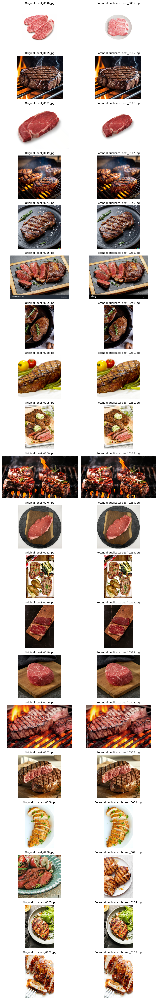

In [4]:

import matplotlib.pyplot as plt
from PIL import Image

# Display the first 20 flagged pairs for visual comparison
sample = duplicates_df.head(20)

fig, axes = plt.subplots(
    len(sample), 2,
    figsize=(8, len(sample) * 2.5)
)

for i, (_, row) in enumerate(sample.iterrows()):
    for j, column in enumerate(["matches", "file"]):
        with Image.open(row[column]) as img:
            axes[i, j].imshow(img.copy())

        axes[i, j].axis("off")
        axes[i, j].set_title(
            f"{'Original' if j == 0 else 'Potential duplicate'}: "
            f"{Path(row[column]).name}",
            fontsize=9
        )

plt.tight_layout()
plt.show()


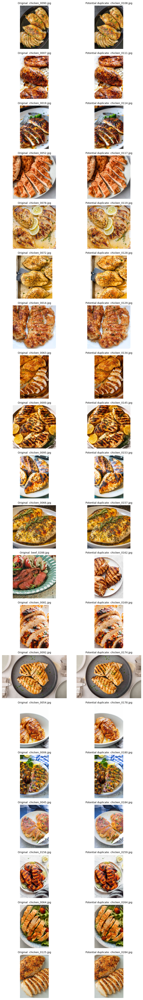

In [5]:

# Display the next 20 potential duplicate pairs
sample = duplicates_df.iloc[20:40]

fig, axes = plt.subplots(len(sample), 2, figsize=(8, len(sample) * 2.5))

for i, (_, row) in enumerate(sample.iterrows()):
    for j, column in enumerate(["matches", "file"]):
        with Image.open(row[column]) as img:
            axes[i, j].imshow(img.copy())

        axes[i, j].axis("off")
        axes[i, j].set_title(
            f"{'Original' if j == 0 else 'Potential duplicate'}: "
            f"{Path(row[column]).name}",
            fontsize=9
        )

plt.tight_layout()
plt.show()


In [6]:

import shutil
from pathlib import Path

# Keep potential duplicates outside the active dataset
QUARANTINE_DIR = IMAGE_DIR.parent / "P2_duplicate_review"
QUARANTINE_DIR.mkdir(parents=True, exist_ok=True)

moved = 0

for file in duplicates_df["file"].unique():
    source = Path(file)

    if source.exists():
        destination = QUARANTINE_DIR / source.parent.name / source.name
        destination.parent.mkdir(parents=True, exist_ok=True)

        shutil.move(str(source), str(destination))
        moved += 1

print(f"Moved {moved} potential duplicates to quarantine.")

for label in manifest["label"].unique():
    remaining = len(list((IMAGE_DIR / label).glob("*.jpg")))
    print(f"{label}: {remaining} images remaining")


Moved 174 potential duplicates to quarantine.
chicken: 319 images remaining
salmon: 313 images remaining
beef: 334 images remaining
shrimp: 308 images remaining
tofu: 295 images remaining


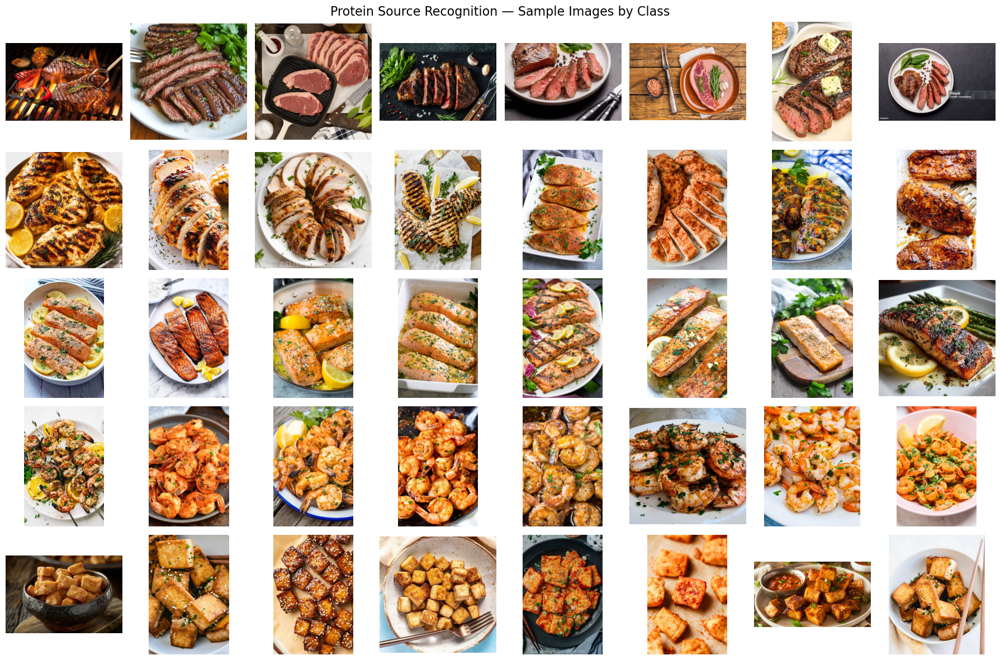

In [9]:

# Display 8 sample images from each protein class

classes = sorted(manifest["label"].unique())
n_samples = 8

fig, axes = plt.subplots(
    len(classes), n_samples,
    figsize=(18, 12)
)

for i, label in enumerate(classes):
    class_files = sorted((IMAGE_DIR / label).glob("*.jpg"))
    sample_files = class_files[:n_samples]

    for j, path in enumerate(sample_files):
        with Image.open(path) as img:
            axes[i, j].imshow(img.convert("RGB"))

        axes[i, j].axis("off")

        if j == 0:
            axes[i, j].set_ylabel(
                label.capitalize(),
                fontsize=12,
                rotation=90
            )

plt.suptitle(
    "Protein Source Recognition — Sample Images by Class",
    fontsize=16
)
plt.tight_layout()
plt.show()


,width,height,aspect_ratio
min,300.0,300.0,0.500000
max,5906.0,4176.0,2.000000
median,1080.0,1200.0,0.775695


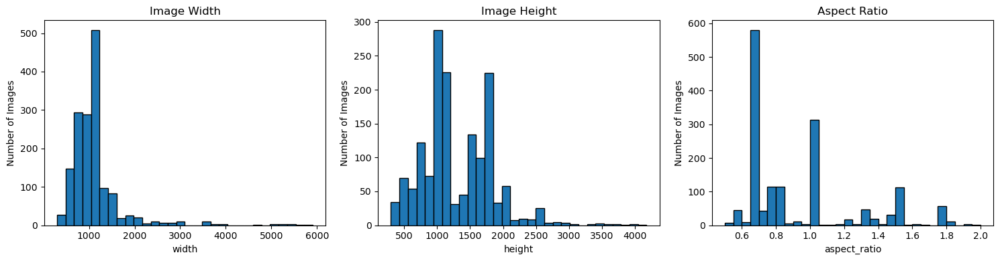

In [10]:

# Analyze image dimensions and aspect ratios
image_stats = []

for label in classes:
    for path in (IMAGE_DIR / label).glob("*.jpg"):
        with Image.open(path) as img:
            width, height = img.size

        image_stats.append({
            "class": label,
            "width": width,
            "height": height,
            "aspect_ratio": width / height
        })

image_stats = pd.DataFrame(image_stats)

# Summary statistics
summary_stats = image_stats[
    ["width", "height", "aspect_ratio"]
].agg(["min", "max", "median"])

display(summary_stats)

# Visualize distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, column, title in zip(
    axes,
    ["width", "height", "aspect_ratio"],
    ["Image Width", "Image Height", "Aspect Ratio"]
):
    ax.hist(image_stats[column], bins=30, edgecolor="black")
    ax.set_title(title)
    ax.set_xlabel(column)
    ax.set_ylabel("Number of Images")

plt.tight_layout()
plt.show()



### Image Dimensions and Aspect Ratio Analysis

The cleaned dataset contains images with considerable variation in dimensions and aspect ratios.

- **Width:** 300–5,906 pixels, with a median of 1,080.
- **Height:** 300–4,176 pixels, with a median of 1,200.
- **Aspect ratio:** 0.50–2.00, with a median of approximately 0.776.

The median aspect ratio indicates that images tend to be slightly taller than they are wide. However, the dataset also contains square and landscape-oriented photographs.

These differences are expected because the images were collected from multiple online sources.

To ensure consistent inputs for our pretrained classification models, all images will be converted to RGB and resized to a standard resolution during preprocessing. We will preserve aspect ratios using padding to avoid distorting the shape of the food.


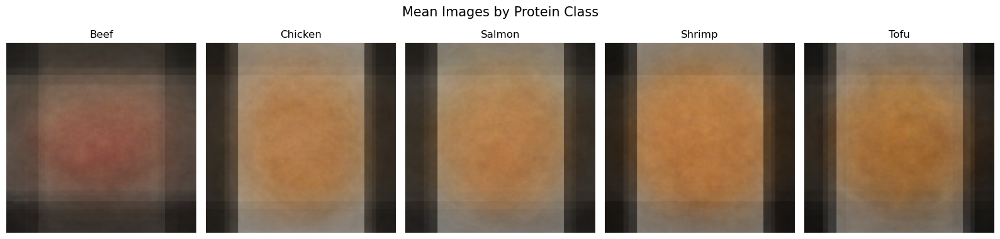

In [11]:

# Generate a mean image for each protein class

TARGET_SIZE = (224, 224)

fig, axes = plt.subplots(1, len(classes), figsize=(16, 4))

for i, label in enumerate(classes):
    class_files = sorted((IMAGE_DIR / label).glob("*.jpg"))
    image_sum = np.zeros((224, 224, 3), dtype=np.float64)

    for path in class_files:
        with Image.open(path) as img:
            img = img.convert("RGB")

            # Preserve aspect ratio and pad to a square
            from PIL import ImageOps
            img = ImageOps.pad(
                img,
                TARGET_SIZE,
                method=Image.Resampling.BILINEAR,
                color=(0, 0, 0)
            )

            image_sum += np.asarray(img, dtype=np.float64)

    mean_image = (
        image_sum / len(class_files)
    ).astype(np.uint8)

    axes[i].imshow(mean_image)
    axes[i].set_title(label.capitalize())
    axes[i].axis("off")

plt.suptitle("Mean Images by Protein Class", fontsize=15)
plt.tight_layout()
plt.show()


### Per-Class Mean Image Analysis

The mean images appear blurry because they represent the average pixel values across hundreds of photographs.

Although individual food items are no longer clearly distinguishable, the visualizations can help identify consistent color distributions, background patterns, and potential dataset biases.

These patterns are important because a classification model could learn to associate certain backgrounds or colors with specific protein sources rather than recognizing the food itself.

We will investigate potential shortcuts further using saliency maps and Grad-CAM in Notebook 4.

,Image Count
label,
beef,334
chicken,319
salmon,313
shrimp,308
tofu,295


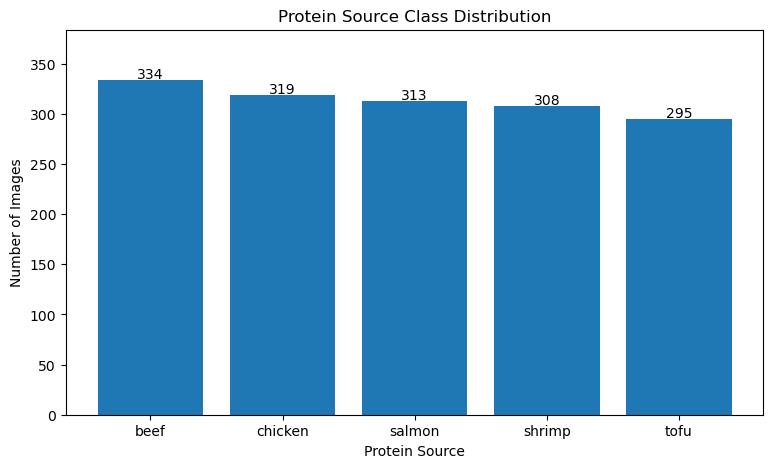

Class imbalance ratio: 1.13


In [3]:

# Check class distribution after cleaning

class_counts = (
    manifest[manifest["kept"] == True]["label"]
    .value_counts()
    .sort_index()
)

display(class_counts.to_frame(name="Image Count"))

plt.figure(figsize=(9, 5))
bars = plt.bar(class_counts.index, class_counts.values)

plt.title("Protein Source Class Distribution")
plt.xlabel("Protein Source")
plt.ylabel("Number of Images")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        str(int(bar.get_height())),
        ha="center"
    )

plt.ylim(0, max(class_counts.values) * 1.15)
plt.show()

print(
    f"Class imbalance ratio: "
    f"{class_counts.max() / class_counts.min():.2f}"
)



### Class Distribution Analysis

After cleaning, the dataset contains 1,569 images across five protein classes.

- Beef: 334
- Chicken: 319
- Salmon: 313
- Shrimp: 308
- Tofu: 295

The class imbalance ratio is 1.13, indicating a relatively balanced dataset. Beef has the most images, while tofu has the fewest.

Given the small difference in class sizes, severe class imbalance is unlikely to be a major concern. We will preserve the current distribution during preprocessing and address any necessary balancing using only the training set in Notebook 3 to prevent data leakage.


Image shape: (224, 224, 3)
Pixel range: 0 to 255


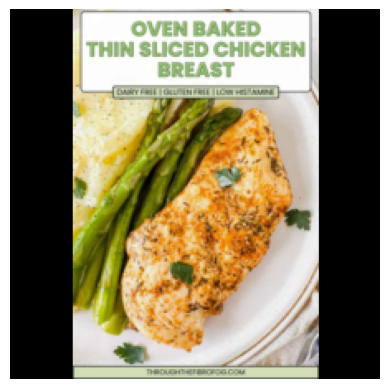

In [4]:

from PIL import ImageOps

TARGET_SIZE = (224, 224)

def preprocess_image(path):
    with Image.open(path) as img:
        img = img.convert("RGB")
        img = ImageOps.pad(
            img,
            TARGET_SIZE,
            method=Image.Resampling.BILINEAR,
            color=(0, 0, 0)
        )
        return np.asarray(img, dtype=np.uint8)

# Test preprocessing on one image
sample_path = next((IMAGE_DIR / "chicken").glob("*.jpg"))
processed = preprocess_image(sample_path)

print("Image shape:", processed.shape)
print("Pixel range:", processed.min(), "to", processed.max())

plt.imshow(processed)
plt.axis("off")
plt.show()



### Image Preprocessing Decisions

All images are converted to three-channel RGB format to ensure consistent color representation across the dataset.

Images are resized to 224 × 224 pixels to provide standardized input dimensions for the pretrained Keras models used in Notebook 3.

We preserve the original aspect ratio using padding rather than stretching or cropping. Stretching could distort the shape and texture of protein sources, while cropping could remove important visual features.

Black padding may introduce artificial borders, so we will investigate whether the models rely on these regions during the explainability analysis in Notebook 4.

Images are stored as unsigned 8-bit integers with raw pixel values ranging from 0 to 255. Model-specific normalization will be applied separately in Notebook 3.


In [5]:

from sklearn.model_selection import train_test_split

# Use only images that survived cleaning
clean_data = manifest[manifest["kept"] == True].copy()

# Create a consistent label-to-index mapping
class_names = sorted(clean_data["label"].unique())
label_to_index = {
    label: i for i, label in enumerate(class_names)
}

# Stratified 80/20 split
train_df, test_df = train_test_split(
    clean_data,
    test_size=0.20,
    stratify=clean_data["label"],
    random_state=42
)

print("Training images:", len(train_df))
print("Testing images:", len(test_df))
print("\nLabel mapping:", label_to_index)

print("\nTraining distribution:")
print(train_df["label"].value_counts().sort_index())

print("\nTesting distribution:")
print(test_df["label"].value_counts().sort_index())


Training images: 1255
Testing images: 314

Label mapping: {'beef': 0, 'chicken': 1, 'salmon': 2, 'shrimp': 3, 'tofu': 4}

Training distribution:
label
beef       267
chicken    255
salmon     250
shrimp     247
tofu       236
Name: count, dtype: int64

Testing distribution:
label
beef       67
chicken    64
salmon     63
shrimp     61
tofu       59
Name: count, dtype: int64


In [6]:

import json

# Save processed data outside the GitHub repository
OUTPUT_DIR = IMAGE_DIR.parent / "P2_processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def prepare_dataset(df):
    images = []
    labels = []

    for row in df.itertuples():
        path = IMAGE_DIR / row.label / row.filename
        images.append(preprocess_image(path))
        labels.append(label_to_index[row.label])

    return (
        np.stack(images).astype(np.uint8),
        np.array(labels, dtype=np.int32)
    )

# Process training and testing images separately
X_train, y_train = prepare_dataset(train_df)
X_test, y_test = prepare_dataset(test_df)

# Save raw 0-255 pixel arrays
np.save(OUTPUT_DIR / "X_train.npy", X_train)
np.save(OUTPUT_DIR / "y_train.npy", y_train)
np.save(OUTPUT_DIR / "X_test.npy", X_test)
np.save(OUTPUT_DIR / "y_test.npy", y_test)

# Save consistent label mapping
with open(OUTPUT_DIR / "label_mapping.json", "w") as f:
    json.dump(label_to_index, f, indent=4)

print("Processed dataset saved successfully!")
print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)
print("Labels:", label_to_index)
print("Saved to:", OUTPUT_DIR)


Processed dataset saved successfully!
Training images: (1255, 224, 224, 3)
Testing images: (314, 224, 224, 3)
Labels: {'beef': 0, 'chicken': 1, 'salmon': 2, 'shrimp': 3, 'tofu': 4}
Saved to: /Users/timhamilton/MSDS565_data/P2_processed



### Train/Test Split and Data Export

The cleaned dataset of 1,569 images was divided into training and testing sets using an 80/20 stratified split with `random_state=42`.

- **Training set:** 1,255 images
- **Testing set:** 314 images

Stratification preserves approximately the same class proportions in both sets, ensuring that each protein source is represented during training and evaluation.

The split was performed before any class balancing or data augmentation to prevent data leakage between training and testing.

All images were converted to RGB, resized to 224 × 224 pixels using aspect-ratio-preserving padding, and saved as NumPy arrays containing raw pixel values from 0 to 255.

The processed datasets were saved outside the GitHub repository in `MSDS565_data/P2_processed`:

- `X_train.npy` and `y_train.npy`
- `X_test.npy` and `y_test.npy`
- `label_mapping.json`

The label-to-index mapping is:

- Beef: 0
- Chicken: 1
- Salmon: 2
- Shrimp: 3
- Tofu: 4

The same preprocessing strategy and label mapping will be reused in subsequent notebooks and the Streamlit application to ensure consistent predictions.
